# Figure 7d. Two colocalized MS4A-locus signals for AD

Stacked locus plots of the chr11 MS4A region (~59.7-60.6 Mb): AD GWAS, microglia and DLPFC *MS4A4A* *cis*-eQTL, microglia *MS4A6A* *cis*-eQTL and DLPFC *MS4A4E* *cis*-eQTL. The y-axis is -log10 marginal p. Two AD-focal ColocBoost colocalization sets are highlighted: CoS1 (blue; top variant chr11:60310703:A:G, shared with the *MS4A4A*/*MS4A6A* eQTLs) and CoS2 (green; top variant chr11:60171834:T:G, shared with the DLPFC *MS4A4E* eQTL). min r between the two sets is the minimum absolute LD correlation between their variants (ColocBoost `cos_purity$min_abs_cor`). The gene track shows only the genes labelled in the published panel.

Input: `data/Figure_7d_MS4A_locus.rds`

In [1]:
library(ggplot2)
library(patchwork)
dat <- readRDS("data/Figure_7d_MS4A_locus.rds")
loc <- dat$locus
head(loc)
## variants per trait and number highlighted in each colocalized set (CoS)
table(loc$trait, ifelse(is.na(loc$cos), "background", loc$cos))
dat$genes[dat$genes$in_figure, ]
## minimum absolute LD between CoS1 and CoS2
round(dat$min_abs_cor_CoS1_CoS2, 2)

,trait,variant,position,neg_log10_p,cos,cos_colour
,<fct>,<chr>,<dbl>,<dbl>,<chr>,<chr>
1,Alzheimer's disease GWAS,chr11:59713479:G:A,59713479,0.8774170,NA,NA
2,Alzheimer's disease GWAS,chr11:59713496:A:G,59713496,1.2620863,NA,NA
3,Alzheimer's disease GWAS,chr11:59713646:G:T,59713646,2.0775764,NA,NA
4,Alzheimer's disease GWAS,chr11:59714308:A:G,59714308,0.1082314,NA,NA
5,Alzheimer's disease GWAS,chr11:59714390:T:C,59714390,2.0647966,NA,NA
6,Alzheimer's disease GWAS,chr11:59714461:GA:G,59714461,1.8841799,NA,NA


                           
                            CoS1 CoS2 background
  Alzheimer's disease GWAS   102  111       1388
  Microglia MS4A4A cis-eQTL  102    0       1499
  DLPFC MS4A4A cis-eQTL      102    0       1499
  Microglia MS4A6A cis-eQTL  102    0       1499
  DLPFC MS4A4E cis-eQTL        0  111       1490

,gene,chrom,start,end,strand,in_figure,highlight
,<chr>,<chr>,<int>,<int>,<chr>,<lgl>,<lgl>
11,MS4A3,chr11,60056587,60071115,+,TRUE,FALSE
12,MS4A2,chr11,60088261,60098467,+,TRUE,FALSE
13,MS4A6A,chr11,60172014,60184666,-,TRUE,TRUE
14,MS4A4A,chr11,60185657,60318080,+,TRUE,TRUE
15,MS4A4E,chr11,60200270,60243137,-,TRUE,TRUE
16,MS4A6E,chr11,60334831,60396596,+,TRUE,FALSE
17,MS4A7,chr11,60378485,60395951,+,TRUE,FALSE
18,MS4A14,chr11,60378530,60417756,+,TRUE,FALSE
19,MS4A5,chr11,60429572,60455214,+,TRUE,FALSE


[1] 0.44

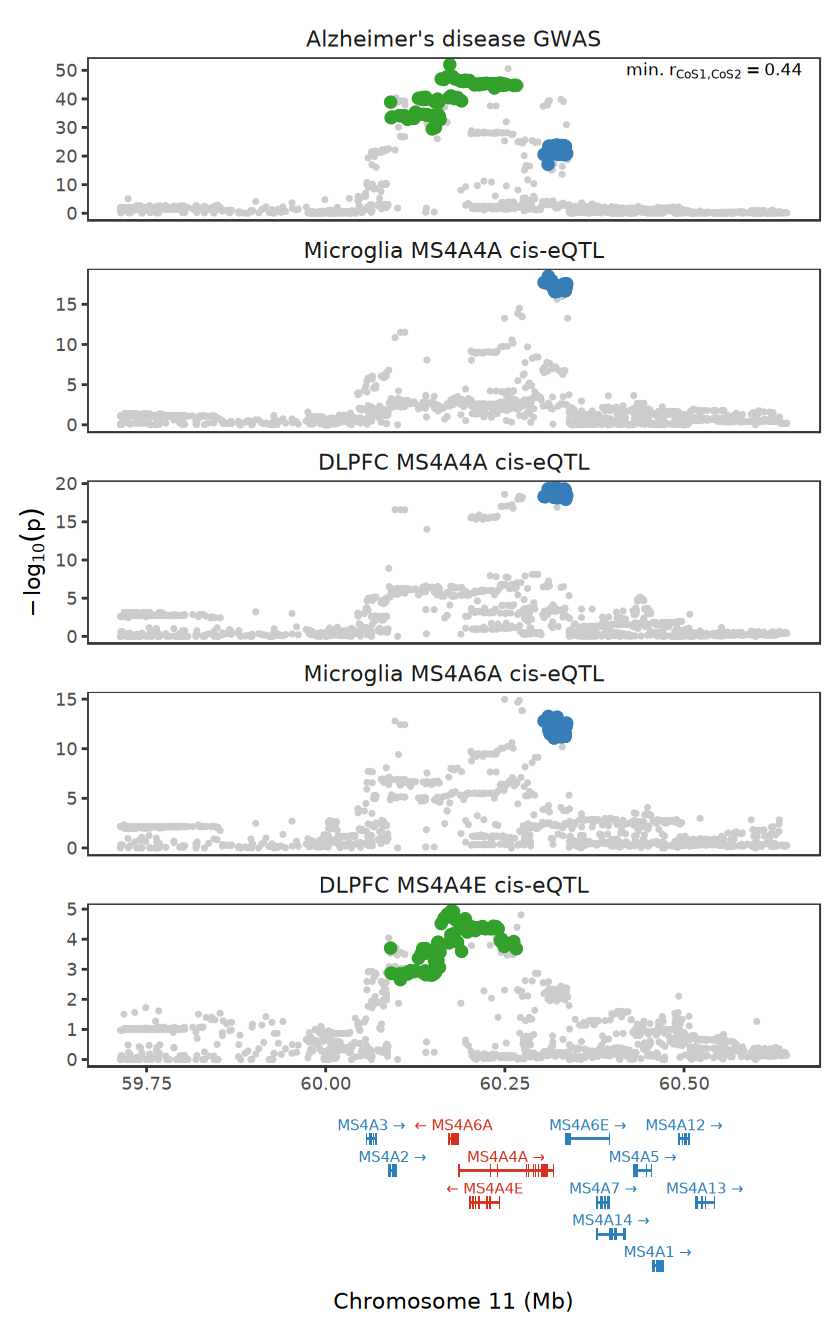

In [2]:

locus_plot <- function(dat, chrom_label, track_height = 1, annot = NULL) {
  loc  <- dat$locus
  xlim <- range(loc$position) / 1e6
  bg <- loc[is.na(loc$cos), ]
  fg <- loc[!is.na(loc$cos), ]
  cos_pal <- unique(fg[, c("cos", "cos_colour")])
  cos_pal <- setNames(cos_pal$cos_colour, cos_pal$cos)

  p_loc <- ggplot() +
    geom_point(data = bg, aes(position / 1e6, neg_log10_p), colour = "grey80", size = 0.8) +
    geom_point(data = fg, aes(position / 1e6, neg_log10_p, colour = cos), size = 2.6) +
    scale_colour_manual(values = cos_pal, guide = "none") +
    facet_wrap(~trait, ncol = 1, scales = "free_y") +
    coord_cartesian(xlim = xlim) +
    labs(x = NULL, y = expression(-log[10](p))) +
    theme_bw(base_size = 13) +
    theme(panel.grid = element_blank(), strip.background = element_blank(),
          strip.text = element_text(size = 13))
  if (!is.null(annot)) p_loc <- p_loc + annot

  ## gene track: only genes drawn in the published panel, packed into rows
  genes <- dat$genes[dat$genes$in_figure, ]
  genes <- genes[order(genes$start), ]
  pad <- diff(xlim) * 1e6 * 0.08
  row_end <- numeric(0); genes$row <- NA
  for (i in seq_len(nrow(genes))) {
    r <- which(row_end < genes$start[i] - pad)[1]
    if (is.na(r)) r <- length(row_end) + 1
    row_end[r] <- genes$end[i]; genes$row[i] <- r
  }
  genes$label <- ifelse(genes$strand == "+", paste0(genes$gene, " →"), paste0("← ", genes$gene))
  exons <- dat$exons[dat$exons$gene %in% genes$gene, ]
  exons$row <- genes$row[match(exons$gene, genes$gene)]
  exons$highlight <- genes$highlight[match(exons$gene, genes$gene)]
  hl <- c(`TRUE` = "#D7301F", `FALSE` = "#2C7FB8")

  p_gene <- ggplot(genes) +
    geom_segment(aes(x = start / 1e6, xend = end / 1e6, y = -row, yend = -row, colour = highlight),
                 linewidth = 0.6) +
    geom_rect(data = exons, aes(xmin = start / 1e6, xmax = end / 1e6, ymin = -row - 0.18,
                                ymax = -row + 0.18, fill = highlight)) +
    geom_text(aes(x = (start + end) / 2e6, y = -row + 0.45, label = label, colour = highlight), size = 3) +
    scale_colour_manual(values = hl, guide = "none") +
    scale_fill_manual(values = hl, guide = "none") +
    scale_y_continuous(expand = expansion(add = c(0.4, 0.7))) +
    coord_cartesian(xlim = xlim) +
    labs(x = chrom_label) +
    theme_void(base_size = 13) +
    theme(axis.title.x = element_text(margin = margin(t = 4)))

  p_loc / p_gene + plot_layout(heights = c(nlevels(loc$trait), track_height))
}

annot <- geom_text(data = data.frame(trait = factor(levels(loc$trait)[1], levels = levels(loc$trait))),
                   aes(x = Inf, y = Inf,
                       label = sprintf("min.~r[CoS1*','*CoS2]==%.2f", dat$min_abs_cor_CoS1_CoS2)),
                   parse = TRUE, hjust = 1.1, vjust = 1.3, size = 3.5)
p <- locus_plot(dat, "Chromosome 11 (Mb)", track_height = 0.9, annot = annot)
options(repr.plot.width = 7, repr.plot.height = 11)
p